# Runner Notebook 2

In [10]:
library(ggplot2)

In [11]:
project_root <- if (file.exists("R/part2.R")) "." else ".."
project_root <- normalizePath(project_root, winslash = "/", mustWork = TRUE)
stopifnot(file.exists(file.path(project_root, "R/part2.R")))

read_height_gwas <- function(file = file.path(project_root, "data/raw/Height.gwas.txt.gz")) {
  gwas <- read.delim(file)

  # Keep SNPs with stronger evidence of association with height and reliable imputation quality
  keep <- gwas$P <= 0.001 & gwas$INFO > 0.8

  candidates <- gwas[
    which(keep),
    c("CHR", "BP", "SNP", "A1", "A2", "P", "OR")
  ]
  candidates$weight <- log(candidates$OR)

  candidates
}

In [12]:
read_height_bim <- function(file) {
  read.table(
    file,
    col.names = c("CHR", "SNP", "CM", "BP", "A1", "A2"),
    colClasses = c("integer", "character", "NULL", "integer",
                   "character", "character")
  )
}

In [13]:
match_height_positions <- function(gwas) {
  tiffany <- read_height_bim(file.path(project_root, "data/processed/Tiffany_autosomes_GRCh37.bim"))

  reference_files <- file.path(
    project_root,
    "data/processed/LDREF",
    paste0("1000G.EUR.", 1:22, ".bim")
  )
  
  # Combines 22 Chromosom BIM files to SNP reference table
  reference <- NULL
  for (file in reference_files) {
    chromosome_table <- read_height_bim(file)
    reference <- rbind(reference, chromosome_table)
  }

  # Create chromosome-position keys to match GWAS weights with the
  # corresponding SNPs in Tiffany's and the 1000 Genomes genotype files.
  positions <- list(
    gwas = paste(gwas$CHR, gwas$BP, sep = ":"),
    tiffany = paste(tiffany$CHR, tiffany$BP, sep = ":"),
    reference = paste(reference$CHR, reference$BP, sep = ":")
  )

  # Drop repeated positions so match() cannot select the wrong SNP
  # when multiple variants share the same chromosome and base-pair position.
  unique_positions <- lapply(positions, function(x) {
    x[!duplicated(x) & !duplicated(x, fromLast = TRUE)]
  })
  shared <- Reduce(intersect, unique_positions)

  gwas_rows <- match(shared, positions$gwas)
  tiffany_rows <- match(shared, positions$tiffany)
  reference_rows <- match(shared, positions$reference)

  data.frame(
    gwas[gwas_rows, ],
    tiffany_bim_row = tiffany_rows,
    tiffany_a1 = tiffany$A1[tiffany_rows],
    tiffany_a2 = tiffany$A2[tiffany_rows],
    reference_snp = reference$SNP[reference_rows],
    reference_a1 = reference$A1[reference_rows],
    reference_a2 = reference$A2[reference_rows]
  )
}

In [14]:
align_height_alleles <- function(matches) {
  tiffany_genotypes <- BEDMatrix::BEDMatrix(
    file.path(project_root, "data/processed/Tiffany_autosomes_GRCh37.bed"),
    simple_names = TRUE
  )
  # Allele order determined by the .bim file
  tiffany_a1_copies <- as.numeric(
    tiffany_genotypes[1, matches$tiffany_bim_row, drop = FALSE]
  )

  reference_matches <-
    (matches$reference_a1 == matches$A1 & matches$reference_a2 == matches$A2) |
    (matches$reference_a1 == matches$A2 & matches$reference_a2 == matches$A1)

  tiffany_matches <-
    (matches$tiffany_a1 == matches$A1 & matches$tiffany_a2 == matches$A2) |
    (matches$tiffany_a1 == matches$A2 & matches$tiffany_a2 == matches$A1)

  # A dot can mark an unlisted allele in a homozygous call.
  tiffany_homozygous <- matches$tiffany_a1 == "." &
    tiffany_a1_copies == 0 &
    (matches$tiffany_a2 == matches$A1 | matches$tiffany_a2 == matches$A2)

  keep <- reference_matches & !is.na(tiffany_a1_copies) &
    (tiffany_matches | tiffany_homozygous)

  aligned <- matches[keep, , drop = FALSE]
  a1_copies <- tiffany_a1_copies[keep]

  # If the effect allele is in Tiffany's A2 column, count copies as 2 minus A1.
  aligned$tiffany_effect_copies <- ifelse(
    aligned$tiffany_a2 == aligned$A1,
    2 - a1_copies,
    a1_copies
  )

  aligned
}

In [15]:
clump_height_chromosome <- function(aligned, chromosome, output_dir) {
  variants <- aligned[aligned$CHR == chromosome, , drop = FALSE]

  reference_prefix <- file.path(
    project_root, "data/processed/LDREF", paste0("1000G.EUR.", chromosome)
  )
  dir.create(output_dir, recursive = TRUE, showWarnings = FALSE)
  output_prefix <- file.path(output_dir, paste0("chr", chromosome))
  clump_input <- paste0(output_prefix, "_clump_input.tsv")

  write.table(
    data.frame(ID = variants$reference_snp, P = variants$P),
    clump_input,
    sep = "\t", quote = FALSE, row.names = FALSE
  )

  # Clumping done with plink2's clump command
  status <- system2(file.path(project_root, "bin/plink2.exe"), c(
    "--bfile", shQuote(reference_prefix),
    "--clump", shQuote(clump_input),
    "--clump-p1", "0.001",
    "--clump-r2", "0.1",
    "--clump-kb", "250",
    "--out", shQuote(output_prefix)
  ))

  if (status != 0) {
    stop("PLINK clumping failed on chromosome ", chromosome)
  }

  clumps <- read.delim(paste0(output_prefix, ".clumps"))
  lead_rows <- match(clumps$ID, variants$reference_snp)
  variants[lead_rows, , drop = FALSE]
}

In [16]:
score_height_chromosome <- function(clumped, chromosome) {
  reference_file <- file.path(
    project_root,
    "data/processed/LDREF",
    paste0("1000G.EUR.", chromosome, ".bed")
  )
  genotypes <- BEDMatrix::BEDMatrix(reference_file, simple_names = TRUE)

  # Representing 0, 1, 2 copies of GWAS effect (reference) allele
  # One row per individual, one column per SNP
  effect_copies <- as.matrix(
    genotypes[, clumped$reference_snp, drop = FALSE]
  )

  # BEDMatrix counts reference A1. Switch counts when the GWAS effect allele is A2
  effect_is_a2 <- clumped$reference_a2 == clumped$A1
  effect_copies[, effect_is_a2] <- 2 - effect_copies[, effect_is_a2, drop = FALSE]

  # Sum the weighted effect-allele counts to get one PRS per person
  reference_scores <- as.numeric(effect_copies %*% clumped$weight)
  names(reference_scores) <- rownames(genotypes)
  tiffany_score <- sum(clumped$tiffany_effect_copies * clumped$weight)

  list(reference_scores = reference_scores, tiffany_score = tiffany_score)
}

In [17]:
run_height_prs <- function(output_dir, chromosomes = 1:22) {
  if (dir.exists(output_dir)) {
    stop("Choose a new output directory for the clumping results.")
  }

  gwas <- read_height_gwas()
  matches <- match_height_positions(gwas)
  aligned <- align_height_alleles(matches)

  reference_totals <- NULL
  tiffany_total <- 0
  n_snps <- 0

  # For every chromosome, clump and then score
  # Then add up the height scores for each individual
  for (chromosome in chromosomes) {
    clumped <- clump_height_chromosome(aligned, chromosome, output_dir)
    scores <- score_height_chromosome(clumped, chromosome)

    if (is.null(reference_totals)) {
      reference_totals <- scores$reference_scores
    } else {
      reference_totals <- reference_totals +
        scores$reference_scores[names(reference_totals)]
    }

    tiffany_total <- tiffany_total + scores$tiffany_score
    n_snps <- n_snps + nrow(clumped)
  }

  list(
    reference_scores = reference_totals,
    tiffany_score = tiffany_total,
    n_snps = n_snps
  )
}

Extracting number of samples and rownames from Tiffany_autosomes_GRCh37.fam...

Extracting number of variants and colnames from Tiffany_autosomes_GRCh37.bim...

Extracting number of samples and rownames from 1000G.EUR.1.fam...

Extracting number of variants and colnames from 1000G.EUR.1.bim...

Extracting number of samples and rownames from 1000G.EUR.2.fam...

Extracting number of variants and colnames from 1000G.EUR.2.bim...

Extracting number of samples and rownames from 1000G.EUR.3.fam...

Extracting number of variants and colnames from 1000G.EUR.3.bim...

Extracting number of samples and rownames from 1000G.EUR.4.fam...

Extracting number of variants and colnames from 1000G.EUR.4.bim...

Extracting number of samples and rownames from 1000G.EUR.5.fam...

Extracting number of variants and colnames from 1000G.EUR.5.bim...

Extracting number of samples and rownames from 1000G.EUR.6.fam...

Extracting number of variants and colnames from 1000G.EUR.6.bim...

Extracting number of samples 

Tiffany's percentile: 57.67


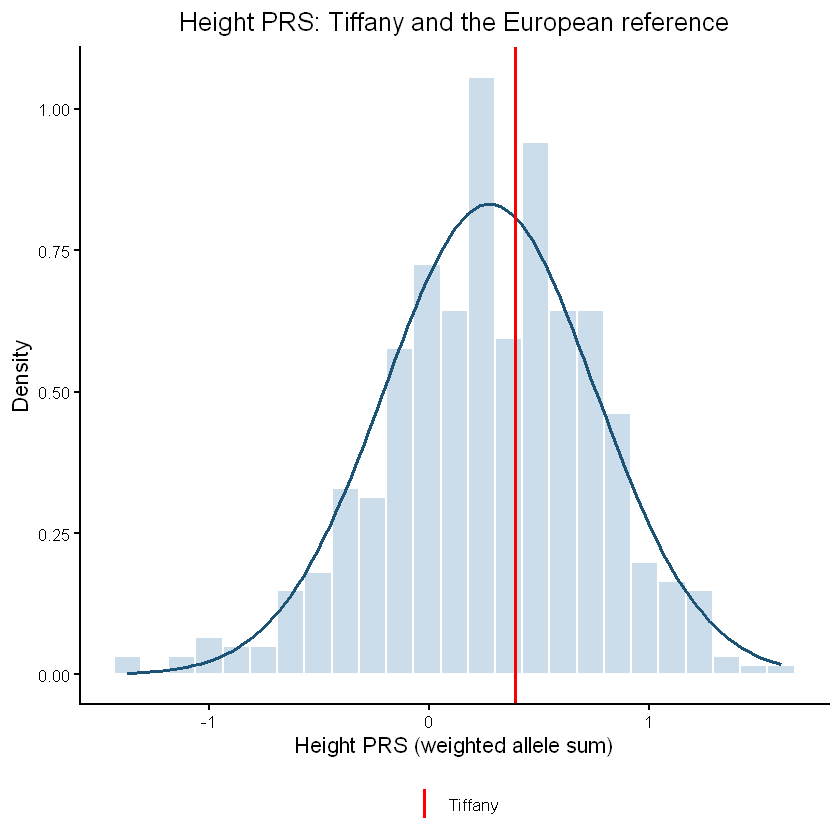

In [18]:
prs <- run_height_prs(tempfile("height-prs-"))
percentile <- 100 * mean(prs$reference_scores < prs$tiffany_score)

reference <- data.frame(score = prs$reference_scores)
tiffany <- data.frame(score = prs$tiffany_score)

p <- ggplot(reference, aes(x = score)) +
  geom_histogram(
    aes(y = after_stat(density)),
    bins = 25,
    fill = "#CBDDEB",
    color = "white"
  ) +
  stat_function(
    fun = dnorm,
    args = list(mean = mean(reference$score), sd = sd(reference$score)),
    color = "#1C5273",
    linewidth = 1
  ) +
  geom_vline(
    data = tiffany,
    aes(xintercept = score, color = "Tiffany"),
    linewidth = 1
  ) +
  scale_color_manual(name = NULL, values = c(Tiffany = "red")) +
  labs(
    title = "Height PRS: Tiffany and the European reference",
    x = "Height PRS (weighted allele sum)",
    y = "Density"
  ) +
  theme_classic(base_size = 13) +
  theme(
    plot.title = element_text(hjust = 0.5),
    legend.position = "bottom"
  )

derived_dir <- file.path(project_root, "data/derived")
dir.create(derived_dir, showWarnings = FALSE)
ggsave(
  filename = file.path(derived_dir, "Tiffany_height_PRS.png"),
  plot = p,
  width = 10, height = 6, units = "in",
  dpi = 300, bg = "white"
)

cat(sprintf("Tiffany's percentile: %.2f\n", percentile))
p